In [51]:
# Using CRISPRi environment

import trenchripper as tr

import warnings
warnings.filterwarnings(action="once")

import matplotlib
matplotlib.rcParams["figure.figsize"] = [20, 10]

# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

import pandas as pd
import glob
import os
import h5py
import skimage as sk
import numpy as np
import matplotlib.pyplot as plt

import utilities

In [52]:
HEADPATH = '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/'
dask_wd = "/home/lag36/scratch/lag36/dask"
headpath_in = HEADPATH + '/run_drift_corrected/'
headpath_out = HEADPATH + '/run_drift_corrected_aligned/'

In [53]:
filenames_per_fov_in = utilities.group_filenames_per_fov(headpath_in, pattern="*")
# filenames_per_fov_out = utilities.generate_output_filenames_dict_per_fov(filenames_per_fov_in, headpath_out)

In [54]:
# Check integrity
N_FOVS = 629
N_TIMEPOINTS = 10
N_SEGMENTATION = 5
assert len(filenames_per_fov_in) == N_FOVS
assert np.all(np.array([len(filenames) for filenames in filenames_per_fov_in.values()]) == N_TIMEPOINTS*N_SEGMENTATION)

In [55]:
def translate_single_image(image,
                           drift_x,
                           drift_y):
    transform_matrix = sk.transform.AffineTransform(
    translation=(drift_x, drift_y)
    )

    transformed_image = sk.transform.warp(
        image,
        transform_matrix,
        mode='constant',  # or 'reflect', depending on your needs
        preserve_range=True, # to keep the original pixel values
        cval = np.median(image)).astype(image.dtype)
    return transformed_image
    
def translate_and_save_single_image(filename_in,
                                    filename_out,
                                    drift_x,
                                    drift_y,):
    with h5py.File(filename_in, 'r') as f:
        image = f['data'][:]
    transformed_image = translate_single_image(image, drift_x, drift_y)
    with h5py.File(filename_out, 'w') as f:
        f.create_dataset('data', data=transformed_image,  dtype='uint16')
    return 0

def list_all_filenames_single_fov(images_path, fov):
    filename_pattern = f'fov={fov}_config=*_t=*.hdf5'
    file_list = glob.glob(os.path.join(images_path,filename_pattern))#
    return file_list

def translate_and_save_all_images_single_fov(fov,
                                             filenames_per_fov_in,
                                             drift_correction_table,):
    """
    Translate and save all images for a single fov
    """
    drift_x = drift_correction_table.loc[fov, 'dx']
    drift_y = drift_correction_table.loc[fov, 'dy']
    # print(drift_x, drift_y)

    for filename_in in filenames_per_fov_in[fov]:
        filename_out = os.path.join(headpath_out, os.path.basename(filename_in))
        # print(filename_in)
        # print(filename_out)
        # print('\n')
        translate_and_save_single_image(filename_in, filename_out, drift_x, drift_y)

    return 0

In [56]:
# Load the drift (this is what experiment was moved to match barcodes)
drift_correction = pd.read_csv('/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/Drift_Correction/drift_metadata.csv',
                               index_col=1
                               ).drop(columns=['Unnamed: 0'])
drift_correction

,dx,dy
FOV,,
0,-2.807018,-4.912281e+00
1,-2.105263,5.684342e-14
2,-2.105263,5.684342e-14
3,-0.701754,5.684342e-14
4,-0.701754,5.684342e-14
...,...,...
624,-8.421053,-3.508772e+00
625,-8.421053,-3.508772e+00
626,-8.421053,-3.508772e+00


In [57]:
# fov = 628
# translate_and_save_all_images_single_fov(fov,
#                                              filenames_per_fov_in,
#                                              drift_correction,)

In [60]:
indices = filenames_per_fov_in.keys()
assert indices == set(range(N_FOVS))

In [41]:
dask_wd = "/home/lag36/scratch/lag36/dask"
dask_controller = tr.trcluster.dask_controller(
    walltime="0:30:00",
    local=False,
    n_workers=200,
    n_workers_min=20,
    memory="2GB",
    working_directory=dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

20m
0:30:00


In [61]:
df_futures = utilities.deploy_function_in_dask(dask_controller = dask_controller, 
                                               headpath=HEADPATH,
                                               function=translate_and_save_all_images_single_fov,
                                               indices=indices,
                                               filenames_per_fov_in=filenames_per_fov_in,
                                                  drift_correction_table=drift_correction)

In [66]:
df_futures.head(1)

,index,status,done,result,exception,key
0,0,finished,True,0,None,translate_and_save_all_images_single_fov-01713...


In [70]:
from nd2reader import ND2Reader

In [71]:
def crop_single_fov_from_nd2(nd2_filename,
                            fov_index,
                            do_cropping,
                            crop_x,
                            crop_y,
                            crop_width,
                            crop_height):

    with ND2Reader(nd2_filename) as nd2file:
        # num_views = nd2file.sizes['v']
        first_frame = nd2file.get_frame_2D(t=0, v=0)
        # dtype = first_frame.dtype

        frame = nd2file.get_frame_2D(t=0, v=fov_index)

        if do_cropping:
            frame = frame[crop_y:crop_y + crop_height, crop_x:crop_x + crop_width]

    return frame

def lead_and_crop_hdf5_image(file_path, 
                             crop_x, crop_y, crop_width, crop_height,
):

    with h5py.File(file_path, 'r') as hf:
        # Read the dataset from the HDF5 file
        image = hf['data'][:]
        # Crop the image
        image_cropped = image[crop_y:crop_y + crop_height, crop_x:crop_x + crop_width]
        # print(f"Processed file {i+1}/{num_files}: {file_path}")
    return image_cropped

In [81]:
nd2_filename = HEADPATH + '/Drift_Correction/Experiment_crop_FOV-All_T-Last.nd2'

# Define the cropping parameters as variables
crop_x = 1000  # Replace with your desired top-left x-coordinate
crop_y = 650  # Replace with your desired top-left y-coordinate
crop_width = 400  # Replace with your desired width
crop_height = 450 # Replace with your desired height

# Load uncorrected and corrected barcode images
fov = 500
index_file = 41
filenames_in = list_all_filenames_single_fov(headpath_in, fov)
print(len(filenames_in), filenames_in)
filenames_out = list_all_filenames_single_fov(headpath_out, fov)
print(len(filenames_out), filenames_out)
filename_before = filenames_in[41]
filename_after = filenames_out[41]

50 ['/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03//run_drift_corrected/fov=500_config=BF_t=1.hdf5', '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03//run_drift_corrected/fov=500_config=BF_t=10.hdf5', '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03//run_drift_corrected/fov=500_config=BF_t=2.hdf5', '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03//run_drift_corrected/fov=500_config=BF_t=3.hdf5', '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03//run_drift_corrected/fov=500_config=BF_t=4.hdf5', '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03//run_drift_corrected/fov=500_config=BF_t=5.hdf5', '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03//run_drift_corrected/fov=500_config=BF_t=6.hdf5', '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03//run_drift_corrected/fov=500_config=BF_t=7.hdf5', '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03//run_drift_corrected/fov=500_config=BF_t=8.hdf

In [82]:
experiment_image = \
crop_single_fov_from_nd2(nd2_filename = nd2_filename,
                            fov_index = fov,
                            do_cropping = True,
                            crop_x = crop_x,
                            crop_y = crop_y,
                            crop_width = crop_width,
                            crop_height = crop_height
                            )

image_cropped_in = lead_and_crop_hdf5_image(filename_before,
                                            crop_x, crop_y, crop_width, crop_height)
image_cropped_out = lead_and_crop_hdf5_image(filename_after,
                                             crop_x, crop_y, crop_width, crop_height)

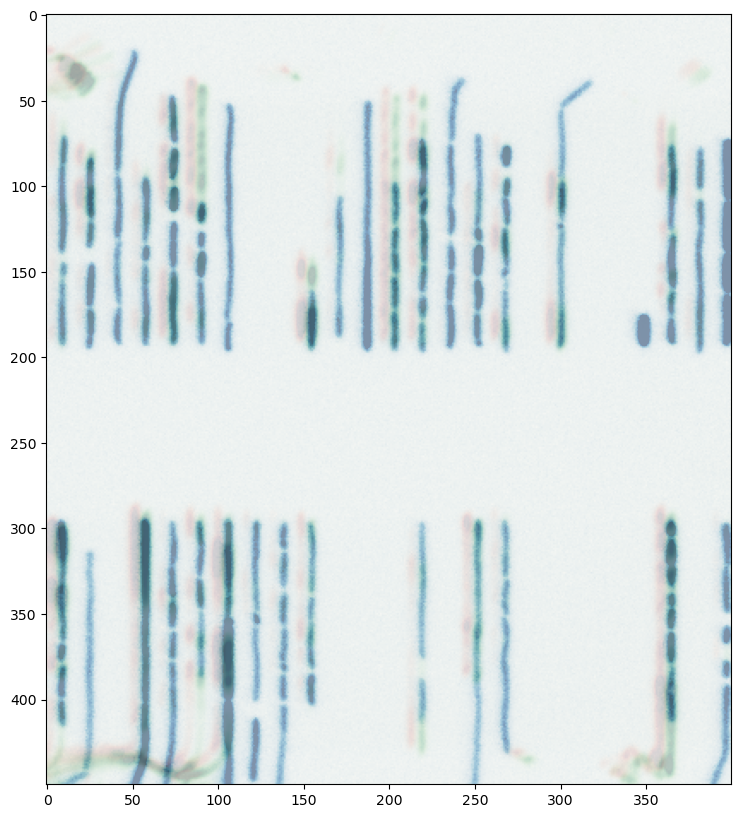

In [83]:
plt.imshow(image_cropped_in, cmap='Reds', vmin = 3000, vmax = 25000, alpha = 0.5)
plt.imshow(image_cropped_out, cmap='Greens', vmin = 3000, vmax = 25000, alpha = 0.5)
plt.imshow(experiment_image, cmap='Blues', vmin = 300, vmax = 1500, alpha = 0.5)

In [1]:
pd.read_hdf(headpath_in + 'metadata_1.hdf5')

NameError: name 'pd' is not defined